# 📘 Notebook 13: PhasmaNet, Staged Token Refinement for Tabular Data

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Paper: Tsioulis, Tefas and Stergioulas (2026)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** The whole notebook ran in about **77 minutes** on a laptop processor (4 threads) that was busy with other work at the same time: 22 minutes for PhasmaNet on California housing, 16 minutes on the Friedman function, 12 minutes on the robot arm and 27 minutes for the ablation's 8 trainings. An idle laptop is much faster: an earlier run without the robot section took 27 minutes for the parts that took 65 minutes here. A Colab GPU shortens the training sections further. To fit a laptop, the networks here are **32 wide with 4 tokens** (about 47,000 weights, 64 wide for the robot arm), trained on 5,000 to 16,500 rows, while the paper's model is 128 wide with 8 tokens and was trained on **one million** simulated binaries. The ablation uses two seeds. The gravitational-wave section uses the paper's pretrained model and does not retrain it. Results at this scale show the trends, not the paper's numbers.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain why **tabular data** (rows and columns, like a spreadsheet) is hard for deep learning, and how turning a row into **tokens** lets a Transformer read it
- Build the three parts of PhasmaNet by hand: the **Φ-Stages**, the **Φ-Refractor** and the **Φ-Feedback** passes
- Check that a network written from the paper's description computes exactly the same function as the published library
- Train PhasmaNet with a scikit-learn style `fit` / `predict` interface and compare it honestly with classic models
- Show where the architecture has a real advantage: smooth targets, smooth predictions, meaningful derivatives and inputs that interact, like the joints of a robot arm
- Measure what each part of the architecture contributes with an **ablation study**
- Use the pretrained model of the paper for its scientific application, gravitational waves

> **Prerequisites:** [Notebook 07: The Transformer](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/07_transformer.ipynb) (self-attention and the encoder layer) and [Notebook 04: ResNet](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/04_resnet.ipynb) (shortcuts that add a signal back).
>
> 🔭 **Why this notebook matters:** most data in companies, hospitals and laboratories is tabular, and there gradient-boosted trees, not neural networks, are usually the strongest models. PhasmaNet is a recent research architecture for tabular data, built for a physics problem where a neural network has clear advantages. This last notebook of the course shows how a new architecture is born: a concrete problem, a few design ideas on top of the Transformer, and experiments that check what each idea really adds.

## 1. The paper

> 📄 I. Tsioulis, A. Tefas and N. Stergioulas, *ΦasmaNet: A Staged Spectral Token-Refinement Architecture for Fast Gravitational-Wave Signal-to-Noise Ratio Prediction*, [arXiv:2611.05309](https://arxiv.org/abs/2611.05309) (2026).
>
> 📄 Related: Y. Gorishniy et al., [*Revisiting Deep Learning Models for Tabular Data*](https://arxiv.org/abs/2106.11959), NeurIPS 2021, the benchmark PhasmaNet is compared with, and A. Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762) (2017), the Transformer of Notebook 07.
>
> 📦 Library: `pip install phasmanet`, documentation at [giannis00.github.io/phasmanet](https://giannis00.github.io/phasmanet/), code at [github.com/giannis00/phasmanet](https://github.com/giannis00/phasmanet).

### Intuition first
Gravitational-wave detectors such as LIGO need, again and again, one number for a pair of merging black holes: the **signal-to-noise ratio** (SNR), how loudly the signal stands out of the detector noise. Computing it exactly means simulating the waveform, which is slow when it must be done millions of times. A network that predicts it from the parameters of the system (masses, spins, orientation and so on) answers in a fraction of a millisecond. These numbers form one **table row**, so this is a tabular regression problem.

PhasmaNet (from Greek *φάσμα*, spectrum) reads such a row in four steps:

1. **Tokenizer.** One linear layer turns the row of F numbers into **T tokens** of width D, a short "sentence" that a Transformer can read. Each token can mix all input features.
2. **Φ-Stages.** An ordered cascade of K stages. Each stage is a Transformer encoder layer (self-attention lets the tokens exchange information) followed by a **Φ-Refractor**, which splits every token into a few **subspaces**, transforms each subspace with its own small network and recombines them with learned weights, like a prism that splits light into colours and recombines it.
3. **Φ-Feedback.** After the first pass from the bottom up, the higher stages send their information back **down**: each lower level is corrected by a gated copy of the level above, and the stages are recomputed. This happens R times.
4. **Readout.** The tokens of the top stage are averaged, and a small network produces the prediction.

Steps 2 and 3 are the ideas of the paper. In Section 6 we remove them one at a time to see what they add.

In [ ]:
%pip install -q phasmanet

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import phasmanet

torch.manual_seed(0)
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
print("phasmanet", phasmanet.__version__, "  torch", torch.__version__)

phasmanet 0.1.0   torch 2.14.1+cpu


## 2. The data: California house prices

A classic table: 20,640 districts of California from the 1990 census, 8 numerical features per district, and the target, the median house value in units of 100,000 dollars.

In [2]:
data = fetch_california_housing(as_frame=True)
X = data.data.to_numpy(dtype=np.float32)
y = data.target.to_numpy(dtype=np.float32)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print("train", X_train.shape, " test", X_test.shape)
data.frame.describe().round(2)

train (16512, 8)  test (4128, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


**What we see.** 16,512 districts for training and 4,128 for testing. The features live on very different scales: the median income is around 4, the population reaches 35,682, and the average number of rooms has a maximum of 142, a few strange districts. The target ranges from 0.15 to 5.00, and **5.00 is a ceiling**: every district worth more than 500,000 dollars was recorded as 5.00. Real tables are like this, noisy and imperfect.

## 3. PhasmaNet by hand

We write every part of the network from the description above, with the same names as the paper. Each block takes and returns a tensor of shape **(batch, T tokens, D width)**.

In [3]:
ACT = nn.GELU

class Refractor(nn.Module):
    """Phi-Refractor: split each token into subspaces, transform each one, recombine with learned weights."""
    def __init__(self, dim, num_subspaces=4, dropout=0.1):
        super().__init__()
        base = dim // num_subspaces
        self.sizes = [base + dim - base * num_subspaces] + [base] * (num_subspaces - 1)
        self.blocks = nn.ModuleList([nn.Sequential(nn.Linear(s, s), ACT(), nn.Linear(s, s)) for s in self.sizes])
        self.recombine = nn.Linear(dim, dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        parts = torch.split(x, self.sizes, dim=-1)                       # the "colours" of the prism
        c = torch.cat([blk(p) for blk, p in zip(self.blocks, parts)], dim=-1)
        w = torch.softmax(self.recombine(c), dim=-1)                     # learned weights over the D dimensions
        return c + self.dropout(w * c)

class Stage(nn.Module):
    """Transformer encoder layer (post-norm, as in Vaswani et al.)."""
    def __init__(self, dim, heads=4, dropout=0.1, ffn_mult=4):
        super().__init__()
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.ffn = nn.Sequential(nn.Linear(dim, dim * ffn_mult), ACT(), nn.Linear(dim * ffn_mult, dim))
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.drop1, self.drop2 = nn.Dropout(dropout), nn.Dropout(dropout)

    def forward(self, x):
        a, _ = self.attn(x, x, x)
        x = self.norm1(x + self.drop1(a))
        return self.norm2(x + self.drop2(self.ffn(x)))

class MyPhasmaNet(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, num_tokens=4, num_stages=3, num_feedback=2, heads=4):
        super().__init__()
        self.T, self.D, self.K, self.R = num_tokens, hidden_dim, num_stages, num_feedback
        self.tokenizer = nn.Linear(input_dim, self.T * self.D)
        self.stage_encoders = nn.ModuleList([Stage(self.D, heads) for _ in range(self.K)])
        self.refractors = nn.ModuleList([Refractor(self.D) for _ in range(self.K)])
        self.feedback_gates = nn.ModuleList([nn.Sequential(nn.Linear(self.D, self.D), nn.Sigmoid())
                                             for _ in range(self.K - 1)])
        self.out_norm = nn.LayerNorm(self.D)
        self.head = nn.Sequential(nn.Linear(self.D, self.D), ACT(), nn.Linear(self.D, 1))

    def stage(self, i, x):
        return self.refractors[i](self.stage_encoders[i](x))

    def forward(self, x, trace=False):
        E = [self.tokenizer(x).view(len(x), self.T, self.D)]            # E[0]: the tokens
        for i in range(self.K):                                          # bottom-up pass
            E.append(self.stage(i, E[-1]))
        for r in range(self.R):                                          # Phi-Feedback passes
            for l in range(self.K, 0, -1):                               # top-down: correct level l-1 with level l
                gate = self.feedback_gates[l - 1](E[l]) if l < self.K else torch.sigmoid(E[l])
                E[l - 1] = E[l - 1] + gate * E[l]
            for i in range(self.K):                                      # recompute the stages bottom-up
                E[i + 1] = self.stage(i, E[i])
        if trace:
            print("levels E[0..K]:", [tuple(e.shape) for e in E])
        return self.head(self.out_norm(E[-1]).mean(dim=1))              # readout: average the T tokens

net = MyPhasmaNet(input_dim=8)
xb = torch.tensor(X_train[:5])
print("output:", tuple(net(xb, trace=True).shape))
print("weights:", f"{sum(p.numel() for p in net.parameters()):,}")

levels E[0..K]: [(5, 4, 32), (5, 4, 32), (5, 4, 32), (5, 4, 32)]
output: (5, 1)
weights: 47,425


**What we see.** The tokenizer turns each row into 4 tokens of width 32, and every level keeps that shape: the tokens E[0] and the outputs of the three Φ-Stages E[1], E[2], E[3] are all (5, 4, 32). The readout averages the 4 tokens and gives one number per row. The whole network has **47,425 weights**.

### Is our network the same as the published one?
We build the library's `PhasmaNet` with the same settings, copy our weights into it and feed both networks the same rows. In evaluation mode (no dropout) the outputs must agree.

In [4]:
lib = phasmanet.PhasmaNet(input_dim=8, hidden_dim=32, num_tokens=4, num_stages=3, num_feedback=2, heads=4)
missing = lib.load_state_dict(net.state_dict(), strict=True)
net.eval()
lib.eval()
with torch.no_grad():
    a, b = net(torch.tensor(X_train[:256])), lib(torch.tensor(X_train[:256]))
print(missing)
print("largest difference between the two networks:", (a - b).abs().max().item())

<All keys matched successfully>
largest difference between the two networks: 0.0


**What we see.** **All keys matched successfully**: our network has exactly the same parts with exactly the same names as the library's. With the same weights the largest difference between the two outputs is **0.0**, so the network written from the paper's description and the published code compute the same function, bit for bit.

## 4. Training PhasmaNet, and an honest comparison

The library wraps the network in a scikit-learn style estimator: it standardises inputs and target, holds out 15% of the training rows for **early stopping** (training stops when the validation error has not improved for `patience` epochs) and keeps the best weights. We use the small network of Section 3 (32 wide, 4 tokens) so that it trains on a laptop. The paper's model is 128 wide with 8 tokens.

In [5]:
from phasmanet import PhasmaNetRegressor

def evaluate(name, model, seconds):
    pred = model.predict(X_test).ravel()
    return {"model": name, "R2": r2_score(y_test, pred),
            "RMSE": mean_squared_error(y_test, pred) ** 0.5, "seconds": seconds}

SMALL = dict(hidden_dim=32, num_tokens=4, batch_size=256, max_epochs=40, patience=8, random_state=0)
t = time.time()
pnet = PhasmaNetRegressor(**SMALL).fit(X_train, y_train)
results = [evaluate("PhasmaNet (small)", pnet, time.time() - t)]
print(f"stopped after {pnet.n_epochs_} epochs,", results[-1])

stopped after 40 epochs, {'model': 'PhasmaNet (small)', 'R2': 0.7971095442771912, 'RMSE': 0.5143539483732513, 'seconds': 1319.9626560211182}


**What we see.** Training ran all 40 epochs (the validation error was still improving slowly, so early stopping never triggered) and took **22 minutes**. On the test districts, R² = **0.797**: the model explains about 80% of the variation in house prices, with a typical error (RMSE) of 0.51, about 51,000 dollars.

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

baselines = {
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "MLP (2 x 128)": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(128, 128), early_stopping=True, max_iter=200, random_state=0)),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=0),
}
for name, model in baselines.items():
    t = time.time()
    model.fit(X_train, y_train)
    results.append(evaluate(name, model, time.time() - t))
table = pd.DataFrame(results).set_index("model").round(3)
table

,R2,RMSE,seconds
model,,,
PhasmaNet (small),0.797,0.514,1319.963
Linear regression,0.594,0.727,0.033
MLP (2 x 128),0.792,0.521,31.826
Gradient boosting,0.838,0.459,4.147


**What we see.** An honest result: on this table **gradient boosting wins**, R² **0.838** against **0.797** for PhasmaNet, and it trained in 4 seconds instead of 22 minutes. PhasmaNet is level with an ordinary MLP (0.792), and every nonlinear model is far ahead of linear regression (0.594). This agrees with the large benchmark studies: on noisy everyday tables, boosted trees are very hard to beat. Section 5 shows the kind of table PhasmaNet was designed for.

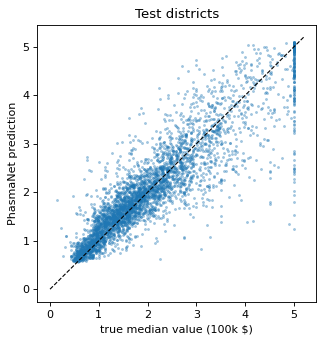

In [7]:
pred = pnet.predict(X_test).ravel()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(y_test, pred, s=3, alpha=0.3)
ax.plot([0, 5.2], [0, 5.2], "k--", lw=1)
ax.set_xlabel("true median value (100k $)")
ax.set_ylabel("PhasmaNet prediction")
ax.set_title("Test districts")
plt.show()

**What we see.** The points follow the diagonal for most districts, with a wider spread for expensive ones. The vertical stripe on the right is the ceiling of the data: districts recorded as 5.00 whose true value was higher, so no model can predict them exactly.

## 5. Where PhasmaNet shines: smooth scientific targets

House prices are noisy: two districts with the same numbers can have very different prices, and the trees of gradient boosting cope well with such data. PhasmaNet was designed for a different kind of table, where the target is a **smooth function** of the inputs, computed by a slow simulation, as the SNR of a gravitational wave is. A standard test of this kind is the **Friedman #1** function (Friedman, 1991):

$$y = 10\sin(\pi x_1 x_2) + 20\,(x_3 - 0.5)^2 + 10\,x_4 + 5\,x_5,$$

with 10 inputs between 0 and 1, of which only the first five matter. We train the same small PhasmaNet and the same baselines on 5,000 rows.

In [8]:
from sklearn.datasets import make_friedman1

Xf, yf = make_friedman1(n_samples=7000, n_features=10, noise=0.0, random_state=0)
Xf, yf = Xf.astype(np.float32), yf.astype(np.float32)
Xf_tr, Xf_te, yf_tr, yf_te = Xf[:5000], Xf[5000:], yf[:5000], yf[5000:]

smooth = {}
t = time.time()
smooth["PhasmaNet (small)"] = (PhasmaNetRegressor(hidden_dim=32, num_tokens=4, batch_size=128, max_epochs=80, patience=12,
                                                  random_state=0).fit(Xf_tr, yf_tr), time.time() - t)
for name, model in [("MLP (2 x 128)", make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(128, 128), early_stopping=True,
                                                                                    max_iter=500, random_state=0))),
                    ("Gradient boosting", HistGradientBoostingRegressor(random_state=0))]:
    t = time.time()
    smooth[name] = (model.fit(Xf_tr, yf_tr), time.time() - t)
pd.DataFrame([{"model": k, "R2": r2_score(yf_te, m.predict(Xf_te).ravel()),
               "RMSE": mean_squared_error(yf_te, m.predict(Xf_te).ravel()) ** 0.5, "seconds": s}
              for k, (m, s) in smooth.items()]).set_index("model").round(4)

,R2,RMSE,seconds
model,,,
PhasmaNet (small),0.9990,0.1522,986.3159
MLP (2 x 128),0.9970,0.2696,12.3181
Gradient boosting,0.9873,0.5513,3.9982


**What we see.** Here the picture changes. PhasmaNet reaches R² = **0.9990** with an RMSE of **0.152**, the MLP **0.270** and gradient boosting **0.551**: the error of PhasmaNet is **3.6 times smaller** than that of gradient boosting and **1.8 times smaller** than that of the MLP. The price is training time, 16 minutes against 4 seconds. On a smooth target, where the answer is a law and not noise, the network's ability to build smooth functions pays off.

### Smooth predictions instead of staircases
We now move one input, \(x_1\), from 0 to 1 and keep the others fixed at 0.5, and plot what each model predicts next to the true function.

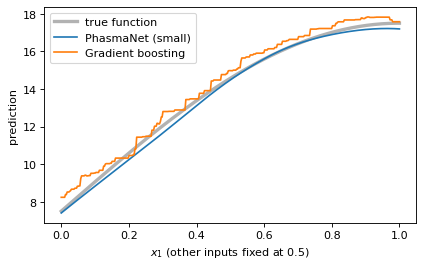

In [9]:
grid = np.linspace(0, 1, 400, dtype=np.float32)
probe = np.full((400, 10), 0.5, dtype=np.float32)
probe[:, 0] = grid
truth = 10 * np.sin(np.pi * grid * 0.5) + 20 * (0.5 - 0.5) ** 2 + 10 * 0.5 + 5 * 0.5
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(grid, truth, "k", lw=3, alpha=0.3, label="true function")
for name in ["PhasmaNet (small)", "Gradient boosting"]:
    ax.plot(grid, smooth[name][0].predict(probe).ravel(), label=name)
ax.set_xlabel("$x_1$ (other inputs fixed at 0.5)")
ax.set_ylabel("prediction")
ax.legend()
plt.show()

**What we see.** Gradient boosting draws a **staircase**: a tree can only predict a constant in each region, so its prediction jumps in small steps and ends above the true curve. PhasmaNet draws a **smooth curve** that follows the true function closely, a little below it at the top end. For a scientist who will feed the predictions into further calculations, the smooth curve is the one that can be trusted.

### Derivatives: how does the output respond to an input?
In science one often needs not only a prediction but its **sensitivity**: how much the output changes when one input changes a little. For the Friedman function the true answer is known: \(\partial y/\partial x_4 = 10\) everywhere. We estimate it from each model by changing \(x_4\) by a small step at 2,000 test points.

In [10]:
h = 0.01
up, down = Xf_te.copy(), Xf_te.copy()
up[:, 3] += h
down[:, 3] -= h
for name in ["PhasmaNet (small)", "Gradient boosting"]:
    m = smooth[name][0]
    slope = (m.predict(up).ravel() - m.predict(down).ravel()) / (2 * h)
    print(f"{name:18s} mean {slope.mean():6.2f}   middle 90% of points from {np.percentile(slope, 5):6.2f} to {np.percentile(slope, 95):6.2f}"
          f"   points with slope exactly 0: {(slope == 0).mean():.0%}")
print("true value: 10 everywhere")

PhasmaNet (small)  mean   9.93   middle 90% of points from   9.23 to  10.62   points with slope exactly 0: 0%
Gradient boosting  mean   9.91   middle 90% of points from  -0.56 to  31.71   points with slope exactly 0: 12%
true value: 10 everywhere


**What we see.** The true slope is 10 everywhere. PhasmaNet's slope averages **9.93**, and for 90% of the test points it lies between **9.23 and 10.62**. Gradient boosting gets the average right (**9.91**) only by luck of averaging: point by point its slope swings from **-0.56 to 31.71**, and at **12%** of the points it is exactly 0, because the small step fell inside one flat region of a tree. A tree ensemble has no useful derivative. A neural network has one everywhere, which matters for sensitivity analysis, optimisation and physics.

### A robot arm: why do the tokens help?
The Friedman function was invented for testing. We now take data from a physical system. The **kin8nm** data set (from the DELVE collection of the University of Toronto) comes from a realistic simulation of a **robot arm with 8 rotating joints**: the inputs are the 8 joint angles, and the target is how far the tip of the arm ends up from a target point. There are 8,192 rows, with some noise added.

Think of how an arm moves. When the shoulder turns, everything after it turns too: the elbow, the wrist and the tip. So the position of the tip is built from sines and cosines of **sums** of angles, and the effect of one joint depends on the angles of all the joints before it. In the language of statistics, the inputs **interact**. Before comparing architectures, we measure how much of this target is interaction. Gradient boosting can be told to build every tree from **one input only** (`interaction_cst="no_interactions"`): the model then becomes a sum of 8 separate curves, one per joint, and cannot represent interactions at all.

In [11]:
from sklearn.datasets import fetch_openml

arm = fetch_openml("kin8nm", version=1, as_frame=False)
Xk, yk = arm.data.astype(np.float32), arm.target.astype(np.float32)
Xk_tr, Xk_rest, yk_tr, yk_rest = train_test_split(Xk, yk, test_size=0.30, random_state=0)
Xk_va, Xk_te, yk_va, yk_te = train_test_split(Xk_rest, yk_rest, test_size=0.50, random_state=0)
print("train", Xk_tr.shape, " validation", Xk_va.shape, " test", Xk_te.shape)

for name, model in [("Linear regression (one flat plane)", LinearRegression()),
                    ("Boosting, one joint per tree (no interactions)", HistGradientBoostingRegressor(interaction_cst="no_interactions", random_state=0)),
                    ("Boosting, free trees (interactions allowed)", HistGradientBoostingRegressor(random_state=0))]:
    model.fit(Xk_tr, yk_tr)
    print(f"{name:48s} R2 on test rows {r2_score(yk_te, model.predict(Xk_te)):.3f}")

train (5734, 8)  validation (1229, 8)  test (1229, 8)
Linear regression (one flat plane)               R2 on test rows 0.391


Boosting, one joint per tree (no interactions)   R2 on test rows 0.388


Boosting, free trees (interactions allowed)      R2 on test rows 0.755


**What we see.** The flat plane of linear regression explains only **39%** of the variation (R² 0.391). Boosting that may use only one joint per tree reaches **0.388**, no better than the flat plane: each joint on its own says almost nothing about where the tip ends up. As soon as the trees may combine joints, R² jumps to **0.755**. So nearly everything that can be learned here comes from how the joints act **together**. A good model for this arm must be good at combining inputs.

Now four models, each with its own way of building a function:

- **Linear regression** draws one flat plane through the data.
- **Gradient boosting** cuts the space of angles into boxes and predicts a constant in each box, so a smooth law becomes a staircase.
- An **MLP** reads all 8 angles at once: every neuron of the first layer takes one weighted sum of them and bends it, and the next layers combine the bent pieces.
- **PhasmaNet** turns the row into a few **tokens**, and in every Φ-Stage the tokens exchange information through self-attention, as the words of a sentence do in Notebook 07. Combining information from different joints is exactly what these exchanges are for.

The two networks are the fair pair: same kind of model, same training by gradient descent, different architecture. Each model uses settings that were picked by trying a few options on the **validation** rows (PhasmaNet 64 wide with 4 tokens and 2 stages, an MLP with three layers of 256, gradient boosting with 31 leaves). The test rows are used once, at the end.

In [12]:
arm_models = {
    "PhasmaNet": PhasmaNetRegressor(hidden_dim=64, num_tokens=4, num_stages=2, max_epochs=300, patience=25, random_state=0),
    "MLP (3 x 256)": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(256, 256, 256), alpha=1e-5, learning_rate_init=1e-3,
                                                                  max_iter=1000, early_stopping=True, n_iter_no_change=30, random_state=0)),
    "Gradient boosting": HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=31, l2_regularization=1.0, max_iter=2000,
                                                       early_stopping=True, validation_fraction=0.15, n_iter_no_change=50, random_state=0),
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
}
arm_rows = []
for name, model in arm_models.items():
    t = time.time()
    if name == "PhasmaNet":
        model.fit(Xk_tr, yk_tr, validation_data=(Xk_va, yk_va))   # early stopping on the validation rows
    else:
        model.fit(Xk_tr, yk_tr)                                    # these stop early on a part of their training rows
    p = model.predict(Xk_te).ravel()
    arm_rows.append({"model": name, "R2": r2_score(yk_te, p), "RMSE": mean_squared_error(yk_te, p) ** 0.5, "seconds": time.time() - t})
pd.DataFrame(arm_rows).set_index("model").round(4)

,R2,RMSE,seconds
model,,,
PhasmaNet,0.9336,0.0674,694.5887
MLP (3 x 256),0.9232,0.0725,28.1951
Gradient boosting,0.8136,0.1130,21.5808
Linear regression,0.3911,0.2042,0.0100


**What we see.** The models rank in the order their way of building a function suggests. The flat plane stays at R² **0.39**. Gradient boosting reaches **0.814** (RMSE 0.113): its boxes catch the interactions only roughly. The two networks are far ahead: the MLP reaches **0.923** (RMSE 0.0725) and PhasmaNet **0.934** with RMSE **0.0674**, an error about 7% smaller than the MLP's and 40% smaller than that of gradient boosting. The price is time again: 12 minutes against 28 seconds for the MLP. Same family, same training, different architecture, and the one whose tokens exchange information comes first on a target made of interactions. One split and one seed are a demonstration, not a proof that the tokens are the reason. Section 6 shows how such a claim is tested.

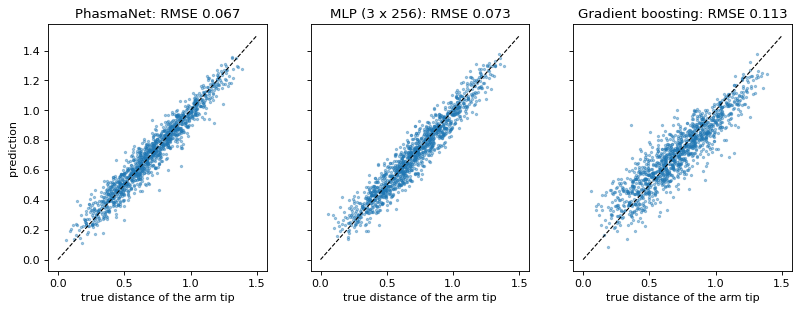

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["PhasmaNet", "MLP (3 x 256)", "Gradient boosting"]):
    p = arm_models[name].predict(Xk_te).ravel()
    ax.scatter(yk_te, p, s=4, alpha=0.4)
    ax.plot([0, 1.5], [0, 1.5], "k--", lw=1)
    ax.set_title(f"{name}: RMSE {mean_squared_error(yk_te, p) ** 0.5:.3f}")
    ax.set_xlabel("true distance of the arm tip")
axes[0].set_ylabel("prediction")
plt.show()

**What we see.** The two networks keep their points in a narrow band along the diagonal, PhasmaNet a little narrower than the MLP. Gradient boosting has a much wider cloud, and at both ends it is pulled towards the middle: it predicts too far for arm positions close to the target and too near for those far away, a typical sign of a model that averages over boxes instead of following a smooth law.

## 6. Ablation: what does each idea add?

An **ablation** removes one part of a model and retrains it, everything else equal. The paper reports a Φ-Refractor OFF ablation on the Covertype benchmark (581,012 rows): accuracy fell from **0.9664** with the Φ-Refractor to **0.9634** without it. Here we repeat the idea at laptop scale, on the smooth Friedman target of Section 5, and we also switch off the feedback. To keep the comparison fair, every variant gets the same budget: 40 epochs, no early stopping, two random seeds.

In [14]:
VARIANTS = {
    "full PhasmaNet": {},
    "no Phi-Refractor": {"use_refractor": False},
    "no Phi-Feedback": {"num_feedback": 0},
    "no Refractor, no Feedback": {"use_refractor": False, "num_feedback": 0},
}
rows = []
for name, change in VARIANTS.items():
    for seed in (0, 1):
        t = time.time()
        m = PhasmaNetRegressor(hidden_dim=32, num_tokens=4, batch_size=128, max_epochs=40, patience=0,
                               random_state=seed, **change).fit(Xf_tr, yf_tr)
        p = m.predict(Xf_te).ravel()
        rows.append({"variant": name, "seed": seed, "R2": r2_score(yf_te, p), "RMSE": mean_squared_error(yf_te, p) ** 0.5,
                     "weights": sum(q.numel() for q in m.module_.parameters()), "seconds": time.time() - t})
ablation = pd.DataFrame(rows)
ablation.groupby("variant", sort=False).agg(R2_mean=("R2", "mean"), RMSE_seed0=("RMSE", "first"), RMSE_seed1=("RMSE", "last"),
                                           weights=("weights", "first"), seconds=("seconds", "mean")).round(4)

,R2_mean,RMSE_seed0,RMSE_seed1,weights,seconds
variant,,,,,
full PhasmaNet,0.9980,0.2291,0.2077,47681,370.1300
no Phi-Refractor,0.9963,0.3253,0.2670,42785,178.5753
no Phi-Feedback,0.9974,0.2586,0.2386,47681,111.6661
"no Refractor, no Feedback",0.9979,0.2350,0.2148,42785,144.7611


**What we see.** The full PhasmaNet is the best variant, R² **0.9980**, with the lowest error in both seeds (RMSE 0.229 and 0.208). Removing only the **Φ-Refractor** hurts the most (RMSE 0.325 and 0.267), and removing only the **Φ-Feedback** also hurts in both seeds (0.259 and 0.239). A surprise: removing **both** gives almost the full model's accuracy (0.235 and 0.215) and trains about 2.5 times faster. At this small scale the two ideas seem to work as a pair: each one alone, without the other, disturbs the network. Two seeds and 5,000 rows cannot settle the question, and the paper's own ablation used far more data. The honest lesson is the method: measure each part, with several seeds, on the kind of data the model is for.

## 7. The application: gravitational-wave SNR

The package contains the model of the paper, trained on one million simulated binary black holes (LIGO Hanford, IMRPhenomXPHM waveforms with precession and higher modes). `optimal_snr` takes physical parameters and returns the SNR. Because the SNR falls exactly as 1 / distance, the distance is applied analytically.

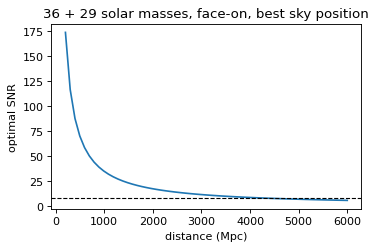

SNR at 410 Mpc: 84.6   SNR at 1000 Mpc: 34.7   SNR = 8 at 4337 Mpc


In [15]:
from phasmanet.gw import optimal_snr, chirp_mass, mass_ratio, spins_from_spherical

def snr(m1, m2, distance):
    n = len(np.atleast_1d(distance))
    one = lambda v: np.full(n, v, dtype=float)
    return optimal_snr(mchirp=one(chirp_mass(m1, m2)), q=one(mass_ratio(m1, m2)), cos_inclination=one(1.0),
                       spin1=spins_from_spherical(one(0.0), one(0.0), one(0.0)),
                       spin2=spins_from_spherical(one(0.0), one(0.0), one(0.0)),
                       f_plus=one(1.0), f_cross=one(0.0), distance=np.atleast_1d(distance).astype(float))

d = np.linspace(200, 6000, 60)
rho = snr(36.0, 29.0, d)
plt.figure(figsize=(5, 3))
plt.plot(d, rho)
plt.axhline(8, color="k", ls="--", lw=1)
plt.xlabel("distance (Mpc)")
plt.ylabel("optimal SNR")
plt.title("36 + 29 solar masses, face-on, best sky position")
plt.show()
rho_1000 = snr(36.0, 29.0, [1000.0])[0]
print(f"SNR at 410 Mpc: {snr(36.0, 29.0, [410.0])[0]:.1f}   SNR at 1000 Mpc: {rho_1000:.1f}   SNR = 8 at {1000 * rho_1000 / 8:.0f} Mpc")

**What we see.** The SNR falls exactly as 1 / distance: **84.6** at 410 Mpc, **34.7** at 1000 Mpc, and it drops to the usual detection threshold of 8 at about **4,340 Mpc**. These numbers are for the most favourable case, a face-on binary directly above the detector. Real events are usually less favourably oriented, so their SNR is lower.

In [16]:
rng = np.random.default_rng(0)
N = 20_000
m1 = rng.uniform(10, 80, N)
m2 = rng.uniform(10, 80, N)
m1, m2 = np.maximum(m1, m2), np.minimum(m1, m2)
args = dict(mchirp=chirp_mass(m1, m2), q=mass_ratio(m1, m2), cos_inclination=rng.uniform(-1, 1, N),
            spin1=spins_from_spherical(rng.uniform(0, 0.9, N), np.arccos(rng.uniform(-1, 1, N)), rng.uniform(0, 2 * np.pi, N)),
            spin2=spins_from_spherical(rng.uniform(0, 0.9, N), np.arccos(rng.uniform(-1, 1, N)), rng.uniform(0, 2 * np.pi, N)),
            f_plus=rng.uniform(-1, 1, N), f_cross=rng.uniform(-1, 1, N), distance=np.full(N, 1000.0))
t = time.time()
rho = optimal_snr(**args)
sec = time.time() - t
print(f"{N:,} SNRs in {sec:.2f} s  ({sec / N * 1e6:.0f} microseconds each)")
print(f"fraction with SNR > 8 at 1000 Mpc: {(rho > 8).mean():.1%}")

20,000 SNRs in 13.90 s  (695 microseconds each)
fraction with SNR > 8 at 1000 Mpc: 68.2%


**What we see.** **20,000 SNRs in 13.9 seconds** on a laptop processor, about **0.7 milliseconds each**, with the paper's full-size model. For this population of binaries (masses 10 to 80 solar masses, random orientations and spins) **68.2%** would be detectable (SNR > 8) at 1000 Mpc. Questions like this, over millions of simulated binaries, are what the surrogate was built for.

## ⚠️ Common pitfalls

- **Expecting a neural network to beat gradient boosting on every table.** On many ordinary tables, boosted trees are as accurate and far cheaper (Section 4). Deep tabular models earn their place when the target is a smooth function, when many predictions are needed fast, or when the model must be part of a larger differentiable system.
- **Forgetting to standardise.** Inputs with very different scales (population in thousands, rooms around 5) slow learning badly. The estimator standardises inputs and target for you. A hand-written loop must do it itself.
- **Trusting one run in an ablation.** Differences of a few thousandths in R² are within the noise of different random seeds, as Section 6 shows. Use several seeds before concluding that a part helps.
- **Copying the paper's size to a small problem.** The paper's 128-wide model with 8 tokens is right for one million training rows. On 16,000 rows a smaller network trains faster and generalises as well.
- **Using the gravitational-wave model outside its training range.** It was trained for one detector, one noise curve and masses from 3 to 170 solar masses. Outside that range it warns that it is extrapolating.

## ✏️ Exercises

### Exercise 1 (More tokens)
Train the small PhasmaNet of Section 5 on the Friedman data again with `num_tokens=8` instead of 4 (same settings otherwise). How do the test RMSE, the number of weights and the training time change?

In [17]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
t = time.time()
m8 = PhasmaNetRegressor(hidden_dim=32, num_tokens=8, batch_size=128, max_epochs=80, patience=12, random_state=0).fit(Xf_tr, yf_tr)
for name, (m, sec) in [("4 tokens", smooth["PhasmaNet (small)"]), ("8 tokens", (m8, time.time() - t))]:
    rmse = mean_squared_error(yf_te, m.predict(Xf_te).ravel()) ** 0.5
    print(f"{name}: RMSE {rmse:.4f}   weights {sum(p.numel() for p in m.module_.parameters()):,}   {sec:.0f} s")
```

*With 8 tokens the error fell from 0.152 to 0.142, a little better, for only 1,408 more weights (the tokenizer simply outputs more tokens, the stages are shared across them). Training took about twice as long (1,228 against 567 seconds in the same session), because attention compares every pair of tokens.*
</details>

### Exercise 2 (Which features does PhasmaNet use?)
Use scikit-learn's `permutation_importance` on the trained `pnet` and the test set: it shuffles one column at a time and measures how much R² drops. Which features matter most?

In [18]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
from sklearn.inspection import permutation_importance
imp = permutation_importance(pnet, X_test, y_test, n_repeats=3, random_state=0)
print(pd.Series(imp.importances_mean, index=data.feature_names).sort_values(ascending=False).round(3))
```

*Location dominates: shuffling Latitude lowers R² by 0.90 and Longitude by 0.80, followed by median income (0.52). Population hardly matters (0.01). In California, where a district lies (coast or inland, city or countryside) says most about its house prices.*
</details>

### Exercise 3 (Classification)
`PhasmaNetClassifier` works the same way for classes. Train it on the breast cancer data set (`sklearn.datasets.load_breast_cancer`, 30 features, 2 classes) with the small settings and 30 epochs, and compare its test accuracy with logistic regression.

In [19]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from phasmanet import PhasmaNetClassifier
Xc, yc = load_breast_cancer(return_X_y=True)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.25, random_state=0, stratify=yc)
clf = PhasmaNetClassifier(hidden_dim=32, num_tokens=4, max_epochs=30, random_state=0).fit(Xc_tr, yc_tr)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xc_tr, yc_tr)
print("PhasmaNet", round(clf.score(Xc_te, yc_te), 3), "  logistic regression", round(logreg.score(Xc_te, yc_te), 3))
```

*Logistic regression wins here, 0.958 against 0.944. With only 426 training tumours and classes that are almost separable by a straight line, a simple linear model is enough, and a deep model has little to add: the same lesson as Section 4, from the other side.*
</details>

## 🔑 Key takeaways

- PhasmaNet turns a table row into a few **tokens** and refines them with an ordered cascade of **Φ-Stages** (a Transformer encoder layer plus a **Φ-Refractor** that splits each token into subspaces and recombines them), then revisits them with gated top-down **Φ-Feedback** passes.
- A network written from the paper's description can be checked against the published library weight by weight: the two gave the same output.
- On a noisy everyday table such as California housing, gradient boosting remains stronger and much cheaper.
- On a **smooth scientific target** PhasmaNet had a 3.6 times smaller error than gradient boosting, smooth predictions instead of staircases and meaningful derivatives: this is the kind of data it was designed for, and the paper reports 99.3% accuracy on gravitational-wave SNRs.
- On the **kin8nm robot arm**, where almost everything depends on how the joints act together, PhasmaNet had a 7% smaller error than an MLP and 40% smaller than gradient boosting.
- An **ablation** with several seeds is the honest way to ask what each part of an architecture adds.
- The same small estimator interface (`fit`, `predict`, `score`) lets a research architecture be used with all the tools of scikit-learn.

---
**This is the last notebook of the course.** From the perceptron of 1958 to an architecture of 2026, every model in this course solved a concrete problem of its time with an idea that could be tested. The best way to continue is the same: take a paper, build its model small, and check every claim with an experiment.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*